# Manim AI Agent

Text to video

# Installation

In [ ]:
#!pip install -q langgraph langchain-google-genai pydantic manim python-dotenv


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Imports

In [ ]:
import os
from typing import List, Optional, Dict, Any, TypedDict
from pydantic import BaseModel, Field
import json
import re
import logging
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import StateGraph, START, END
import subprocess
import tempfile
import shutil
import uuid
from datetime import datetime
from IPython.display import Video, display, Image
import ast

# Pydantic Models & State Schema

In [113]:
class AnimationPrompt(BaseModel):
    description: str = Field(..., description="Topic or concept to animate")
    complexity: str = Field("medium", description="Complexity level: simple, medium, or complex")
    quality: str = Field("medium_quality", description="Render quality"),
    target_duration: float = Field(90.0, description="Desired total video length in seconds")

class AnimationScenario(BaseModel):
    title: str = Field(..., description="Title of the animation")
    objects: List[str] = Field(..., description="Visual elements/objects to include")
    transformations: List[str] = Field(..., description="Animations and transitions to apply")
    equations_or_text: Optional[List[str]] = Field(None, description="Key text or equations to feature")
    storyboard: Optional[List[Dict[str, Any]]] = Field(None, description="Step-by-step storyboard sections")

class AnimationState(TypedDict):
    prompt: str
    complexity: str
    quality: str
    scenario: Optional[Dict[str, Any]]
    raw_code: str
    optimized_code: str
    final_code: str
    video_path: Optional[str]
    is_valid: bool
    error_message: Optional[str]
    retry_count: int
    target_duration: float

# Nodes

In [114]:
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Initialize Gemini LLM
llm = ChatGoogleGenerativeAI(model="gemini-3.6-flash", temperature=0.3)

def _extract_text(content) -> str:
    """Helper to safely convert LLM response content (string or list) into a string."""
    if isinstance(content, list):
        return "".join([item.get("text", str(item)) if isinstance(item, dict) else str(item) for item in content])
    return str(content)

def extract_scenario_node(state: AnimationState) -> Dict[str, Any]:
    """Dynamically extracts a storyboard and visual plan for ANY topic."""
    logger.info(f"--- NODE: Extract Scenario for topic: {state['prompt']} ---")
    prompt = state["prompt"]
    complexity = state["complexity"]
    
    system_prompt = """
    Create an educational animation storyboard for the given topic (can be mathematics, science, computer science, data structures, physics, or general concepts).
    Focus on clear visual storytelling.
    Respond with a JSON object containing:
    - title: A clear, engaging title
    - objects: Visual elements/objects to include (e.g., shapes, text labels, nodes, graphs, icons)
    - transformations: Animation types to use (e.g., "fade_in", "transform", "shift", "grow_arrow")
    - equations_or_text: Key text elements or formulas to feature (can be null)
    - storyboard: 4-6 chronological sections, each with:
      * section_name: Name of section
      * time_range: Estimated timing
      * narration: Explanation text
      * visuals: What appears on screen
      * animations: Specific transitions
    The ENTIRE animation must total approximately {target_duration} seconds. Distribute the time evenly (or with natural pacing) across the sections.
    Only respond with the valid JSON object, nothing else.
    """
    
    messages = [
        ("system", system_prompt.format(target_duration=state["target_duration"])),
        ("user", f"Create an animation storyboard for the topic: '{prompt}'. "
                f"Complexity: {complexity}. Target total duration: {state['target_duration']} seconds.")
    ]
    
    response = llm.invoke(messages)
    content_str = _extract_text(response.content)
    
    try:
        json_match = re.search(r'\{.*\}', content_str, re.DOTALL)
        if json_match:
            return {"scenario": json.loads(json_match.group(0))}
    except Exception as e:
        logger.error(f"Error parsing scenario JSON: {e}")
        
    return {
        "scenario": {
            "title": f"{prompt.capitalize()} Overview",
            "objects": ["text_labels", "shapes", "containers"],
            "transformations": ["fade_in", "move_to"],
            "equations_or_text": None
        }
    }

def generate_code_node(state: AnimationState) -> Dict[str, Any]:
    """Generates clean Manim Python code tailored to the dynamic topic."""
    logger.info("--- NODE: Generate Manim Code ---")
    scenario = state["scenario"]
    prompt = state["prompt"]
    complexity = state["complexity"]
    
    system_prompt = """
    Create professional Manim animation code in Python that visualizes the requested topic clearly and elegantly. Your code MUST:
    1. Use 'from manim import *' at the top.
    2. Create a Scene class named 'ManimScene' extending Scene.
    3. Implement the construct method correctly.
    4. CRITICAL CONSTANTS & API RULES:
       - DO NOT use 'CENTER'. Use 'ORIGIN' for centering objects.
       - Text objects do not take an 'alignment' argument. For center-aligned paragraphs, use Paragraph(..., alignment="center").
    5. Explicitly position elements using move_to(), shift(), or to_edge() to avoid overlaps.
    6. Clean up old elements between sections using self.play(FadeOut(...)) (DO NOT use self.clear()).
    7. Return ONLY valid Python code inside ```python markdown blocks. No extra conversational filler.
    8. Use ONLY objects, methods and constants that exist in the official Manim Community API.
    9. CRITICAL TIMING RULE:
        - The total length of the animation (sum of all run_time arguments + self.wait calls)
            MUST be approximately {target_duration} seconds.
        - Prefer explicit run_time=... on every self.play() and self.wait().
        - Typical pacing: 8-15 s per major section for a {target_duration}s video.
        - Do NOT leave large silent gaps; keep the viewer engaged for the full duration.
    """
    
    messages = [
    ("system", system_prompt.format(target_duration=state["target_duration"])),
    ("user", f"Topic: {prompt}\nTitle: {scenario.get('title')}\n"
             f"Objects: {scenario.get('objects')}\n"
             f"Transformations: {scenario.get('transformations')}\n"
             f"Complexity: {complexity}\n"
             f"Target duration: {state['target_duration']} seconds\n"
             f"Storyboard: {scenario.get('storyboard')}")
    ]
    
    response = llm.invoke(messages)
    content = _extract_text(response.content)
    
    if "```python" in content:
        content = content.split("```python", 1)[1].split("```", 1)[0]
    elif "```" in content:
        content = content.split("```", 1)[1].split("```", 1)[0]
        
    return {"raw_code": content.strip()}

def optimize_layout_node(state: AnimationState) -> Dict[str, Any]:
    """Optimizes layout spacing and element flow."""
    logger.info("--- NODE: Optimize Layout ---")
    code = state["raw_code"]
    
    system_prompt = """
    Review the provided Manim code and ensure optimal layout and flow:
    1. Check for proper spacing (at least 2.0 units between active elements).
    2. Ensure proper cleanup of past elements using FadeOut before introducing new concepts.
    3. Return ONLY the polished Python code inside ```python markdown blocks.
    """
    
    messages = [
        ("system", system_prompt),
        ("user", f"Code to optimize:\n```python\n{code}\n```")
    ]
    
    response = llm.invoke(messages)
    content = _extract_text(response.content)
    
    if "```python" in content:
        content = content.split("```python", 1)[1].split("```", 1)[0]
    elif "```" in content:
        content = content.split("```", 1)[1].split("```", 1)[0]
        
    return {"optimized_code": content.strip(), "final_code": content.strip()}

def validate_code_node(state: AnimationState) -> Dict[str, Any]:
    """Performs static AST checks and semantic rule enforcement on generated Manim code."""
    logger.info("--- NODE: Validate Manim Code (AST & Rules Check) ---")
    code = state["final_code"]
    errors = []
    
    # 1. Check Python Syntax via AST parser
    try:
        ast.parse(code)
    except SyntaxError as e:
        errors.append(f"SyntaxError: {e.msg} at line {e.lineno}")
        
    # 2. Check for required Manim import
    if "from manim import *" not in code:
        errors.append("Missing required import: 'from manim import *'")
        
    # 3. Check for Scene class definition
    if "class " not in code or "Scene" not in code:
        errors.append("Missing Manim Scene class definition (e.g., class MyScene(Scene):)")
        
    # 4. Check for forbidden operations / common hallucinations
    if "self.clear()" in code:
        errors.append("Forbidden method call detected: 'self.clear()' is not supported; use explicit FadeOut animations.")
        
    if "CENTER" in code:
        errors.append("Invalid constant 'CENTER': Manim uses 'ORIGIN' for the center point.")
        
    if errors:
        error_msg = "; ".join(errors)
        logger.warning(f"Validation failed: {error_msg}")
        return {
            "is_valid": False,
            "error_message": error_msg
        }
    else:
        logger.info("Code validation passed successfully.")
        return {
            "is_valid": True,
            "error_message": None
        }

def fix_code_node(state: AnimationState) -> Dict[str, Any]:
    """Automatically fixes syntax, structure, or rule errors in the code using Gemini."""
    logger.info("--- NODE: Fix Manim Code ---")
    code = state["final_code"]
    error_msg = state.get("error_message") or "Unknown validation or runtime error."
    retry_count = state.get("retry_count", 0) + 1
    
    system_prompt = """
    You are an expert Manim and Python debugging assistant.
    Fix the provided Manim code by addressing all identified issues. Follow these guidelines:
    1. Fix all syntax errors and logical mistakes first
    2. Fix positioning issues by adding explicit positioning commands
    3. Resolve element overlaps by repositioning elements with adequate spacing
    4. Implement all positioning suggestions to improve clarity
    5. Maintain the original educational intent and mathematical content
    6. Ensure all animations follow a logical step-by-step flow
    7. Add comments explaining your fixes for complex changes
    Return ONLY the corrected, valid Python code inside ```python markdown blocks.
    """
    
    messages = [
        ("system", system_prompt),
        ("user", f"Code with error:\n```python\n{code}\n```\n\nValidation Errors / Feedback:\n{error_msg}")
    ]
    
    response = llm.invoke(messages)
    content = _extract_text(response.content)
    
    if "```python" in content:
        content = content.split("```python", 1)[1].split("```", 1)[0]
    elif "```" in content:
        content = content.split("```", 1)[1].split("```", 1)[0]
        
    return {
        "final_code": content.strip(),
        "optimized_code": content.strip(),
        "retry_count": retry_count
    }

def should_fix_code(state: AnimationState) -> str:
    """Conditional router: triggers code repair if validation fails and retry limit is respected."""
    if not state.get("is_valid", True) and state.get("retry_count", 0) < 3:
        return "fix"
    return "proceed"

def render_manim_video(code: str, quality: str = "medium_quality") -> str:
    """Renders Manim Python code into an MP4 file with UTF-8 encoding for Windows compatibility."""
    base_temp = os.path.abspath("./tmp_manim")
    output_dir = os.path.abspath("./videos")
    os.makedirs(base_temp, exist_ok=True)
    os.makedirs(output_dir, exist_ok=True)
    
    short_id = str(uuid.uuid4())[:8]
    temp_dir = os.path.join(base_temp, short_id)
    os.makedirs(temp_dir, exist_ok=True)
    
    script_path = os.path.join(temp_dir, "script.py")
    with open(script_path, "w", encoding="utf-8") as f:
        f.write(code)
        
    # Dynamically find the Scene class name from the generated code
    class_name = "ManimScene"
    for line in code.split("\n"):
        if line.strip().startswith("class ") and "Scene" in line:
            class_name = line.strip().split("class ")[1].split("(")[0].strip()
            break
            
    quality_flags = {
        "low_quality": ("-ql", "480p15"),
        "medium_quality": ("-qm", "720p30"),
        "high_quality": ("-qh", "1080p60")
    }
    flag, quality_dir = quality_flags.get(quality, ("-qm", "720p30"))
    
    command = ["manim", flag, "script.py", class_name]
    logger.info(f"Executing command: {' '.join(command)} in {temp_dir}")
    
    result = subprocess.run(
        command, 
        cwd=temp_dir, 
        capture_output=True, 
        text=True, 
        encoding="utf-8", 
        errors="replace"
    )
    
    if result.returncode != 0:
        logger.error(f"Manim render error: {result.stderr}")
        return f"Error: {result.stderr}"
        
    videos_dir = os.path.join(temp_dir, "media", "videos")
    if not os.path.exists(videos_dir):
        return "Error: Video output directory not found."
        
    scene_dirs = [os.path.join(videos_dir, d) for d in os.listdir(videos_dir) if os.path.isdir(os.path.join(videos_dir, d))]
    if not scene_dirs:
        return "Error: Scene directory not found."
        
    scene_dir = max(scene_dirs, key=os.path.getctime)
    target_dir = os.path.join(scene_dir, quality_dir)
    if not os.path.exists(target_dir):
        target_dir = scene_dir
        
    mp4_files = [os.path.join(target_dir, f) for f in os.listdir(target_dir) if f.endswith(".mp4")]
    if not mp4_files:
        return "Error: No MP4 file generated."
        
    video_file = max(mp4_files, key=os.path.getctime)
    timestamp = datetime.now().strftime("%m%d%H%M")
    output_file = os.path.join(output_dir, f"vid_{timestamp}_{short_id}.mp4")
    
    shutil.copy2(video_file, output_file)
    shutil.rmtree(temp_dir, ignore_errors=True)
    
    return output_file

def render_video_node(state: AnimationState) -> Dict[str, Any]:
    """Renders the final code and catches runtime errors for the self-correction loop."""
    logger.info("--- NODE: Render Video & Check Runtime ---")
    code = state["final_code"]
    quality = state.get("quality", "medium_quality")
    
    # Call your existing render_manim_video function
    video_path = render_manim_video(code, quality=quality)
    
    if video_path.startswith("Error:"):
        error_msg = video_path.replace("Error:", "").strip()
        retry_count = state.get("retry_count", 0) + 1
        logger.warning(f"Runtime render failed: {error_msg}")
        return {
            "is_valid": False,
            "error_message": f"RuntimeError/NameError during Manim execution: {error_msg}",
            "retry_count": retry_count,
            "video_path": None
        }
    else:
        logger.info("Video rendered successfully!")
        return {
            "is_valid": True,
            "error_message": None,
            "video_path": video_path
        }

# Compile Graph

In [115]:
# Compile Graph with Validation, Render, & Repair Nodes
workflow = StateGraph(AnimationState)
workflow.add_node("extract_scenario", extract_scenario_node)
workflow.add_node("generate_code", generate_code_node)
workflow.add_node("optimize_layout", optimize_layout_node)
workflow.add_node("validate_code", validate_code_node)
workflow.add_node("fix_code", fix_code_node)
workflow.add_node("render_video", render_video_node)  # <-- New render node

workflow.add_edge(START, "extract_scenario")
workflow.add_edge("extract_scenario", "generate_code")
workflow.add_edge("generate_code", "optimize_layout")
workflow.add_edge("optimize_layout", "validate_code")

# Static validation check router
workflow.add_conditional_edges(
    "validate_code",
    should_fix_code,
    {
        "fix": "fix_code",
        "proceed": "render_video"  # Proceed to render instead of ending
    }
)

# Runtime render check router (catches NameErrors/RuntimeErrors)
workflow.add_conditional_edges(
    "render_video",
    should_fix_code,
    {
        "fix": "fix_code",
        "proceed": END
    }
)

workflow.add_edge("fix_code", "validate_code")

app = workflow.compile()

# LangGraph Diagram

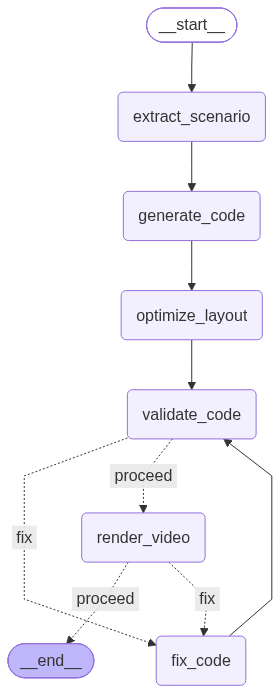

LangGraph workflow rendered successfully!


In [116]:
# Render and display the LangGraph state machine diagram
try:
    png_bytes = app.get_graph().draw_mermaid_png()
    display(Image(png_bytes))
    print("LangGraph workflow rendered successfully!")
except Exception as e:
    print(f"Error drawing graph: {e}")
    print("Note: Ensure you have internet access or the necessary rendering dependencies installed.")

# Initial State

In [117]:
def initial_manim_state(topic: str, complexity: str = "medium", quality: str = "medium_quality") -> dict:
    """
    Passes the initial state into app.invoke(initial_state), since rendering is handled inside the graph
    """
    initial_state = {
        "prompt": topic,
        "complexity": complexity,
        "target_duration": 90.0,
        "quality": quality,
        "scenario": None,
        "raw_code": "",
        "optimized_code": "",
        "final_code": "",
        "video_path": "",
        "is_valid": True,
        "error_message": None,
        "retry_count": 0
    }
    
    # 1. Run LangGraph workflow with validation & self-correction loop
    result = app.invoke(initial_state)
    
    return result

# Initialize Test

In [118]:
test_topic = "How AI Agents Work and State Management with LangGraph"
print(f"Generating animation for: '{test_topic}'...")
output = initial_manim_state(test_topic, complexity="complex", quality="medium_quality")

print("\n--- RESULTS ---")
print(f"Title: {output['scenario'].get('title')}")
print(f"Video Output: {output['video_path']}")

INFO:__main__:--- NODE: Extract Scenario for topic: How AI Agents Work and State Management with LangGraph ---
c:\Users\Mark\magnimind\ai_agent_animation\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
INFO:google_genai.models:AFC is enabled with max remote calls: 10.


Generating animation for: 'How AI Agents Work and State Management with LangGraph'...


INFO:httpx:HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.6-flash:generateContent "HTTP/1.1 200 OK"
INFO:__main__:--- NODE: Generate Manim Code ---
c:\Users\Mark\magnimind\ai_agent_animation\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
INFO:google_genai.models:AFC is enabled with max remote calls: 10.
INFO:httpx:HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.6-flash:generateContent "HTTP/1.1 200 OK"
INFO:__main__:--- NODE: Optimize Layout ---
c:\Users\Mark\magnimind\ai_agent_animation\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
INFO:google_genai.m


--- RESULTS ---
Title: How AI Agents Work and State Management with LangGraph
Video Output: c:\Users\Mark\magnimind\ai_agent_animation\notebooks\videos\vid_10161417_72abfe0f.mp4


# Display Animation

In [119]:
# Check if the video was rendered successfully and display it
video_path = output.get("video_path")

if video_path and not video_path.startswith("Error"):
    print(f"Playing video from: {video_path}")
    # embed=True ensures the video is baked into the notebook notebook file for easy viewing
    display(Video(video_path, embed=True, width=700))
else:
    print(f"Failed to render video: {video_path}")

Playing video from: c:\Users\Mark\magnimind\ai_agent_animation\notebooks\videos\vid_10161417_72abfe0f.mp4
